<table style="border:none;width:100%;table-layout:fixed"><tr style="border:none">
<td style="border:none;text-align:left;vertical-align:middle">
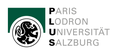</td>
<td style="border:none;text-align:center;vertical-align:middle">
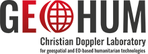</td>
<td style="border:none;text-align:right;vertical-align:middle">
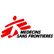</td>
</tr></table>

---

# High-Resolution Urban Heat Mapping - Tondo, Manila
## 02 · Validation

**Christian Doppler Laboratory GEOHUM** - geospatial and EO-based humanitarian technologies
Department of Geoinformatics (Z_GIS), Paris Lodron University of Salzburg · in partnership with **Médecins Sans Frontières**

---

Diagnostics for a completed run: whether the training sample is representative, whether the residuals are unbiased, how much detail the product genuinely adds, and whether accuracy depends on surface type or time of day.

Each analysis returns a table as well as a figure, so results can be compared across runs rather than only read off a chart. Every section is independent - run the ones a given review calls for.

**Requires** `01_pipeline` to have completed for the mode selected below. Section 6 also requires the other mode.

## Setup

The diagnostics operate on the training samples, not on the saved maps, so the pooled arrays must be available. `session.load` restores them - and the fitted model - from disk alone.

Nothing is downloaded and nothing is retrained. The split is regenerated with the same seed and stratification used during training, so every metric reported here matches the pipeline run exactly.

**Requires** `01_pipeline.ipynb` to have completed for this mode.

In [1]:
import sys
from pathlib import Path
for _c in (Path.cwd(), Path.cwd().parent):
    if (_c / "lstpipe").is_dir():
        sys.path.insert(0, str(_c)); break

from lstpipe import Config, session, diagnostics, viz

MODE = "Day"
cfg = Config.manila(mode=MODE)

session.migrate(cfg)          # adopt caches from an earlier version
h, fit = session.load(cfg)          # from disk - no network, no retraining
print("outputs ->", cfg.base_dir)

nothing to migrate
restored manila Day: 35 scenes · 682,769 samples
loaded model trained 2026-10-18 22:03 (10 features)
  model trained 2026-10-18 22:03
  pattern  MAE 2.39 K · RMSE 3.63 K · R² 0.142
absolute MAE 2.39 K · RMSE 3.63 K · R² 0.794   (same error, larger denominator)
  70 maps on disk
outputs -> C:\BUCKET\Advising\Khalid\manila-lst-downscaling


## 1 · Sample composition

Are the temperature extremes represented on both sides of the split, and is the sample representative of the area's land cover?

Watch for a cold bias at the hot end: that is the regression-to-the-mean signature of tree ensembles, expected rather than alarming, but worth quantifying before someone else notices it.

In [2]:
cover = diagnostics.extreme_coverage(cfg, h, fit)

temperature extremes in the split:
       band  threshold_C  n_train  n_test  adequate
coldest 1 %        23.59     4909    1992      True
coldest 5 %        25.59    24142   10352      True
hottest 5 %        50.77    23844   10430      True
hottest 1 %        53.47     4787    2119      True

held-out error by temperature band (anomaly space):
  coldest 5 %  n= 10,352 MAE 4.13 K bias +3.93 K  over-predicts
  middle 90 %  n=184,237 MAE 2.18 K bias +0.02 K  
  hottest 5 %  n= 10,242 MAE 4.32 K bias -4.28 K  under-predicts
  a cold bias at the hot end is the regression-to-the-mean signature of tree ensembles


## 2 · Residual behaviour

A symmetric spread is honest noise. A systematic lean means a whole class of pixels is mis-stated, and that bias propagates into every map.

signed residuals (prediction minus observation, anomaly space):
  positive 95,634 (46.7 %) mean +2.56 K
  negative 109,197 (53.3 %) mean -2.24 K
  overall bias +0.002 K · skew +1.24 · balanced

per-scene bias, most negative and most positive:
      date  utc  n_px  bias_K  pct_positive
2026-01-29 0158  5902   -0.64          36.0
2026-02-02 0028  5955   -0.27          36.3
2025-04-07 2324  5965   -0.20          45.2
2026-07-18 0651  6067    0.16          47.8
2025-08-01 0138  6048    0.19          39.6
2026-05-21 0534  1755    0.26          49.2
residual distribution: mean +0.002 K · std 3.634 K · skew +1.236 · excess kurtosis +5.441
  heavy-tailed tails, right-skewed
  beyond 2σ: observed  5.90 % vs normal  4.55 %  (as expected)
  beyond 3σ: observed  2.05 % vs normal  0.27 %  (heavier)
  beyond 4σ: observed  0.68 % vs normal  0.01 %  (heavier)

 percentile  residual_K
        0.1     -12.584
        1.0      -8.061
        5.0      -5.319
       25.0      -1.714
       50.0      -0.16

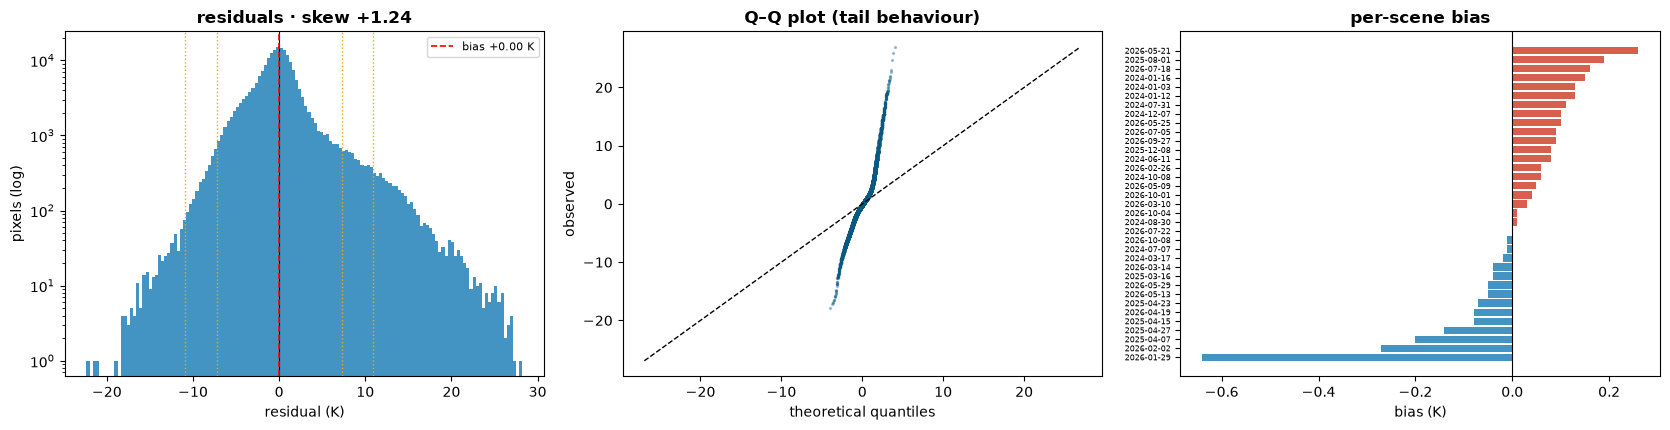

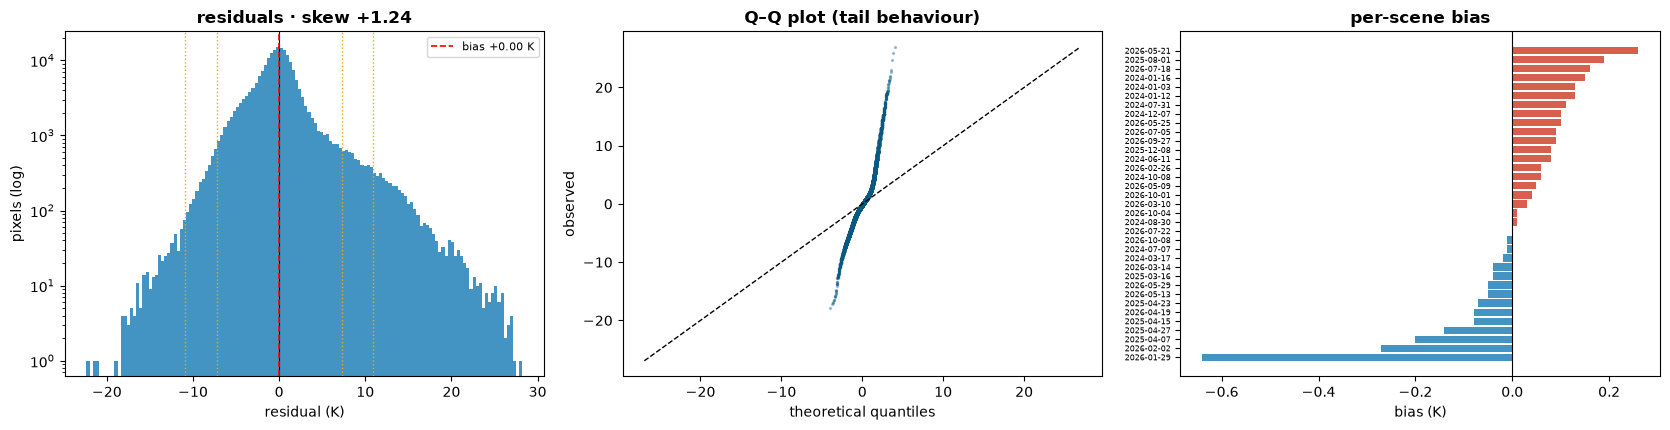

In [3]:
signs = diagnostics.residual_signs(cfg, h, fit)
tails = diagnostics.residual_tails(cfg, h, fit)
by_lc = diagnostics.residual_by_landcover(cfg, h, fit)

viz.residual_panel(cfg, signs["residuals"], signs["by_scene"])

## 3 · How much detail is genuinely added

**There is no 10 m thermal ground truth** - ECOSTRESS observes at 70 m, so a true 10 m residual cannot be computed and any claim otherwise would be circular.

What can be measured: whether the correction conserves mass, and the spread *within* each 70 m cell, which is precisely the structure the product claims to add. The **detail ratio** - that spread divided by the scene's total spread - is the most direct single measure of whether this is downscaling or interpolation. A pure upsample scores zero.

In [4]:
detail = diagnostics.sub_pixel_detail(cfg)

C:\BUCKET\Advising\Khalid\manila-lst-downscaling\lstpipe\diagnostics.py:231: RuntimeWarning: Mean of empty slice
  agg = np.nanmean(blocks, axis=(1, 3))
C:\Users\b1077653\Anaconda\envs\marimo\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


                             scene  closure_mean_K  sub70m_std_K  scene_std_K  detail_ratio
manila_2024-01-03_2354_Day_lst_10m          0.0001         0.356         2.24         0.159
manila_2024-01-12_0958_Day_lst_10m          0.0001         0.388         1.11         0.350
manila_2024-01-16_0823_Day_lst_10m         -0.0001         0.411         1.31         0.314
manila_2024-03-17_0831_Day_lst_10m          0.0001         0.513         1.74         0.294
manila_2024-06-11_0839_Day_lst_10m         -0.0001         0.578         1.80         0.322
manila_2024-07-07_2216_Day_lst_10m         -0.0001         1.142         5.91         0.193
manila_2024-07-31_0242_Day_lst_10m         -0.0004         1.049         5.44         0.193
manila_2024-08-30_0119_Day_lst_10m         -0.0001         1.023         6.27         0.163

mass closure worst |mean| 0.0004 K -> conserved
detail ratio 0.248 - the share of spatial variability that is genuinely sub-pixel (a pure upsample scores 0)


## 4 · Performance by land cover

Does accuracy depend on surface type, and would class-specific models help?

R² per class tracks that class's own spread, so a homogeneous class scores badly for reasons that have nothing to do with the model. Compare MAE across classes instead.

held-out accuracy by land cover (anomaly space):
    lulc  n_test_px  obs_std_K  MAE_K  RMSE_K     R2  bias_K
   Water      12874       4.43  2.622   3.613  0.336   0.044
 Wetland        245       3.50  2.522   3.016  0.259   0.263
    Crop       1632       3.75  2.398   3.454  0.151   0.290
   Grass       2214       3.45  2.191   3.209  0.133  -0.037
Built-up     166878       3.81  2.374   3.639  0.090  -0.028
    Bare       2071       3.77  2.431   3.611  0.081   0.112
    Tree      15415       3.78  2.347   3.634  0.075   0.202
Mangrove        281       4.49  3.444   4.600 -0.051   1.009

  R² tracks each class's own spread (obs_std_K) - compare MAE instead

would class-specific models help?
    lulc   n_px  pooled_MAE_K  class_MAE_K  pooled_R2  class_R2  R2_gain
Built-up 556281         2.309        2.388      0.159     0.095   -0.064
    Tree  51300         2.236        2.358      0.160     0.073   -0.087
    Bare   6764         2.305        2.472      0.143     0.055   -0.088
   W

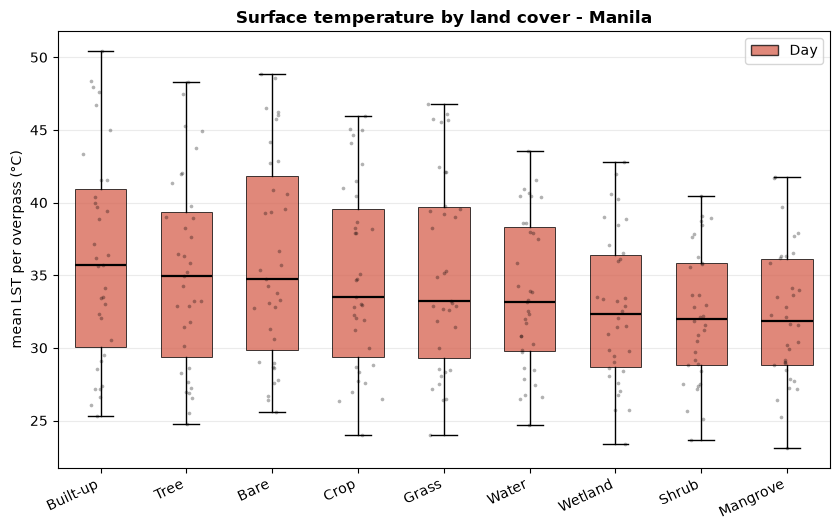

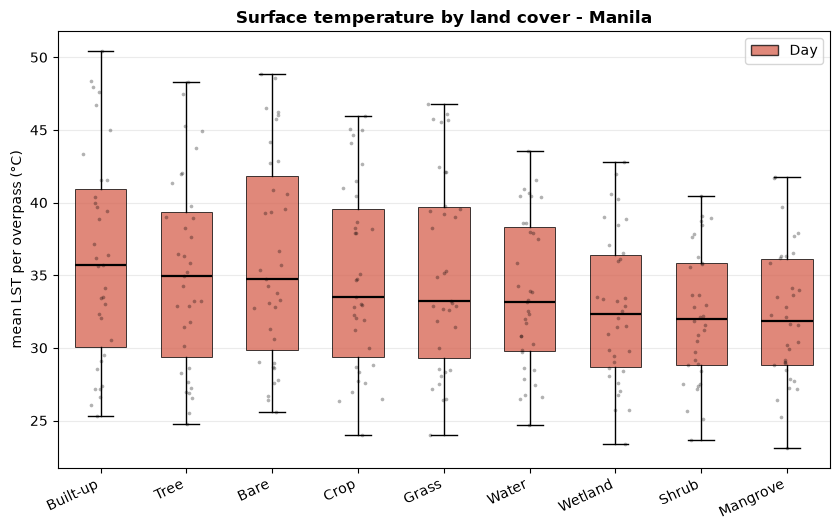

In [5]:
lc = diagnostics.by_landcover(cfg, h, fit)
viz.landcover_boxplots(cfg)

## 5 · Time of day

The acquisition window spans several hours and scene level varies widely across it. If band-specific models outperform a single all-window model, the *spatial pattern* itself depends on time of day - surfaces warming unevenly in the morning behave differently from surfaces cooling in the afternoon.

In [6]:
bands = diagnostics.by_local_hour(cfg, h, fit)

     band local_hours  scenes  samples  pooled_MAE_K  pooled_R2  band_MAE_K  band_R2  R2_gain
  morning       06-09      10   200000          1.40      0.029        1.26    0.154    0.125
   midday       09-15      16   302769          3.52      0.250        3.54    0.226   -0.024
afternoon       15-19       9   180000          1.18     -0.075        1.03    0.173    0.249

mean R² gain from stratifying: +0.117
  band-specific models are measurably better - the spatial pattern itself depends on time of day, not only the temperature level


## 6 · Scene quality and day–night structure

`sharpened_frac` is the share of each map genuinely driven by the model rather than filled from upsampled ECOSTRESS where optical imagery was cloudy. It explains why some maps look blocky, and produces a delivery list.

The day–night comparison needs both products to exist.

Day: 35 scenes graded
  GOOD      35 (100.0 %) sharpened 1.00–1.00
  35 cleared for delivery
  corr(optical gap, sharpened) +nan -> driven by cloud on the day itself, not by the pairing window


C:\Users\b1077653\Anaconda\envs\marimo\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\b1077653\Anaconda\envs\marimo\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


needs both Day and Night zonal statistics


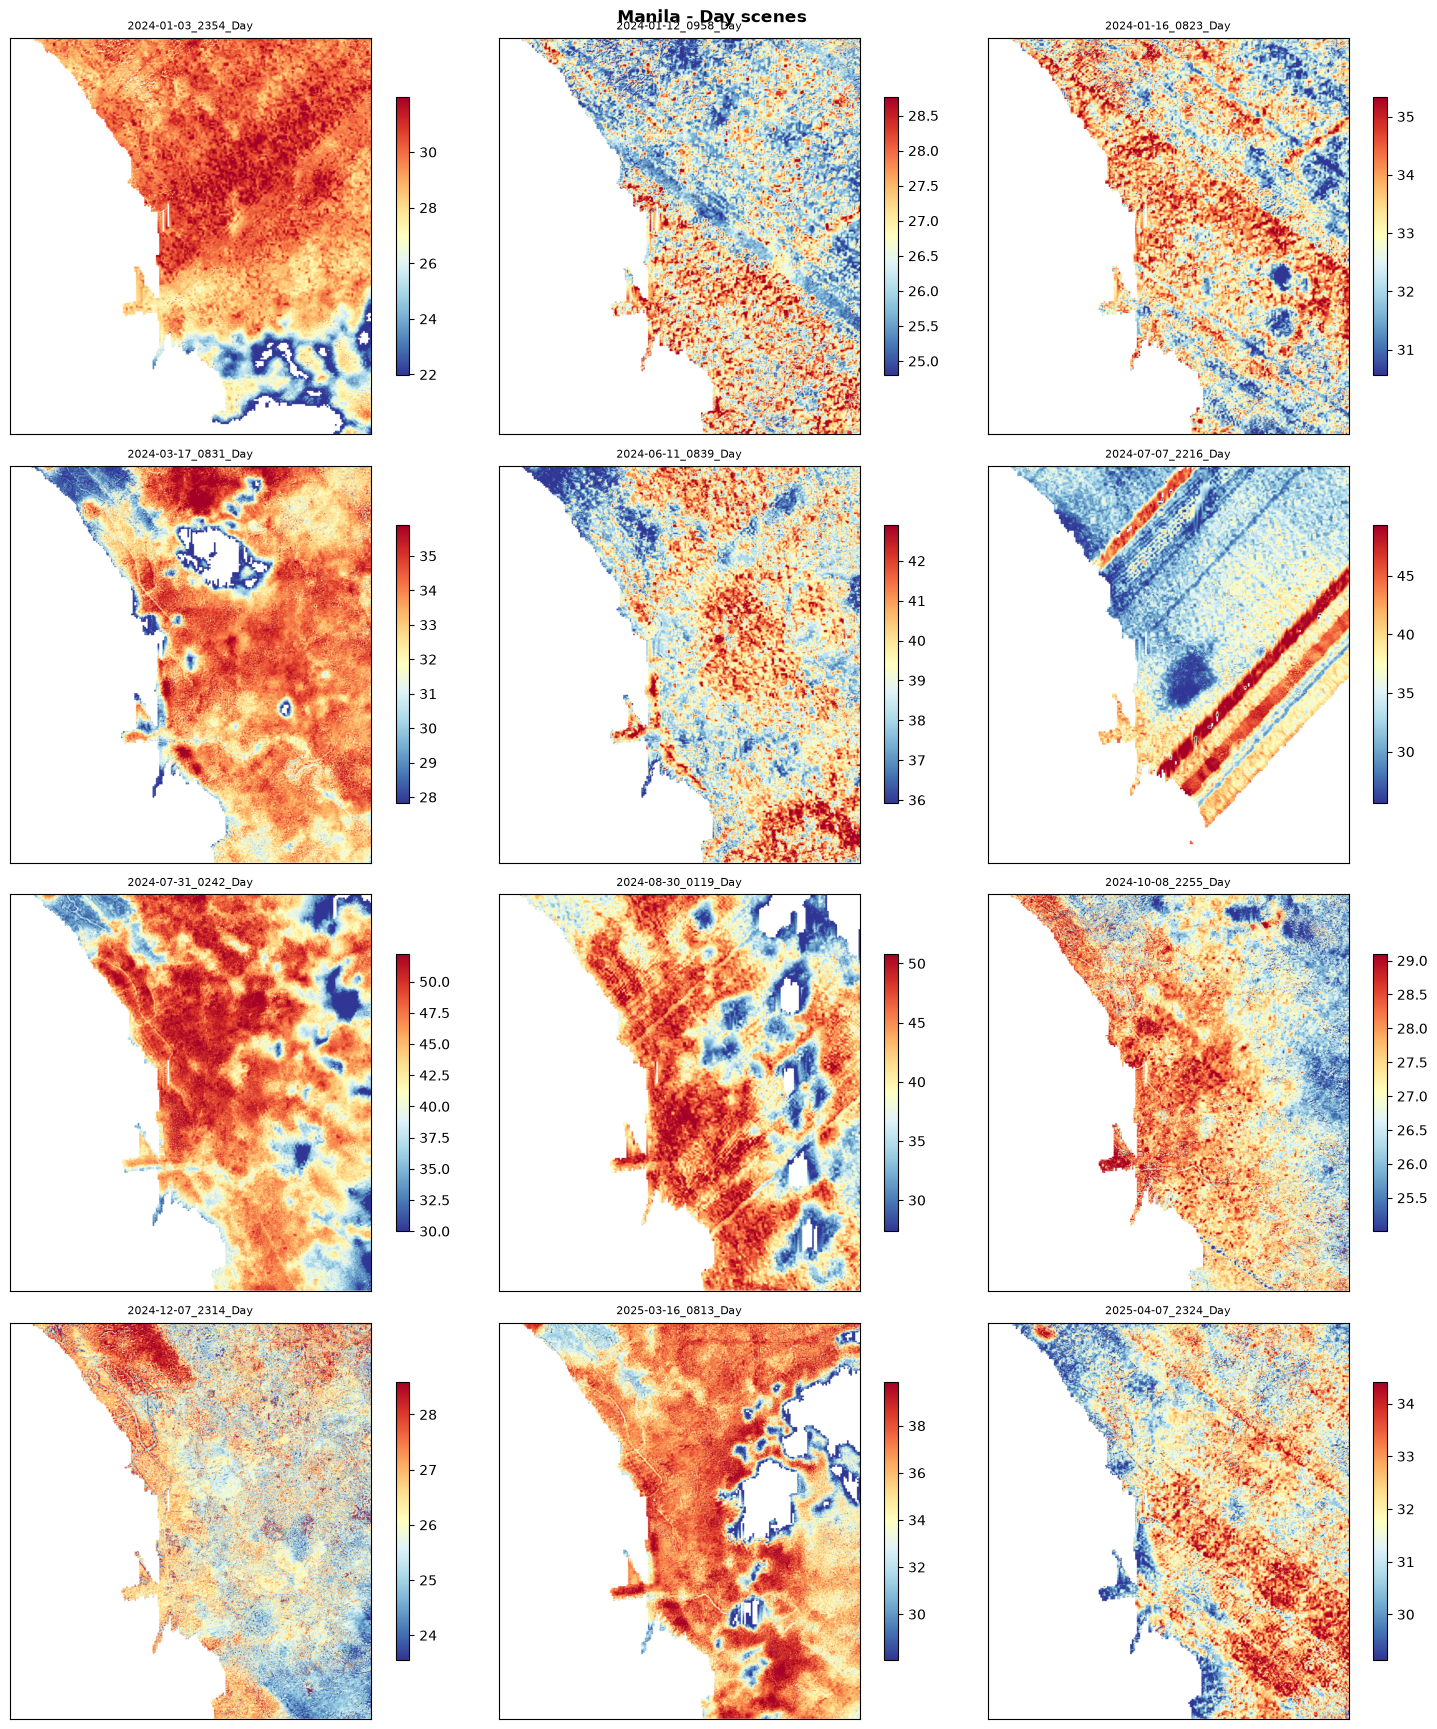

In [7]:
quality = diagnostics.scene_quality(cfg)
viz.contact_sheet(cfg)

deviation = diagnostics.day_night_deviation(cfg)   # needs both modes